In [2]:
#I am doing a data analysis project on credit card fraud, I have a data set called card_transdata.csv. 
#To start off, write code to import the needed libraries such as pandas, seaborn, and matplotlib
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv("card_transdata.csv")

# Display basic information
print(df.head())
print(df.info())

   distance_from_home  distance_from_last_transaction  \
0           57.877857                        0.311140   
1           10.829943                        0.175592   
2            5.091079                             NaN   
3            2.247564                        5.600044   
4           44.190936                        0.566486   

   ratio_to_median_purchase_price  repeat_retailer  used_chip  \
0                        1.945940              1.0        1.0   
1                        1.294219              1.0        NaN   
2                        0.427715              1.0        0.0   
3                        0.362663              1.0        1.0   
4                        2.222767              1.0        1.0   

   used_pin_number  online_order  fraud  
0              0.0           0.0      0  
1              0.0           0.0      0  
2              0.0           1.0      0  
3              0.0           1.0      0  
4              0.0           1.0      0  
<class 'pandas

In [3]:
#next, check for missing values in the dataset
# Check for missing values in each column
print(df.isnull().sum())
# Missing value counts and percentages
missing_count = df.isnull().sum()
missing_percent = (missing_count / len(df)) * 100

missing_df = pd.DataFrame({
    'Missing Count': missing_count,
    'Missing Percentage': missing_percent
})

print(missing_df)

distance_from_home                0
distance_from_last_transaction    3
ratio_to_median_purchase_price    2
repeat_retailer                   7
used_chip                         4
used_pin_number                   2
online_order                      4
fraud                             0
dtype: int64
                                Missing Count  Missing Percentage
distance_from_home                          0            0.000000
distance_from_last_transaction              3            0.300300
ratio_to_median_purchase_price              2            0.200200
repeat_retailer                             7            0.700701
used_chip                                   4            0.400400
used_pin_number                             2            0.200200
online_order                                4            0.400400
fraud                                       0            0.000000


In [4]:
# Drop all rows with null values
df = df.dropna()

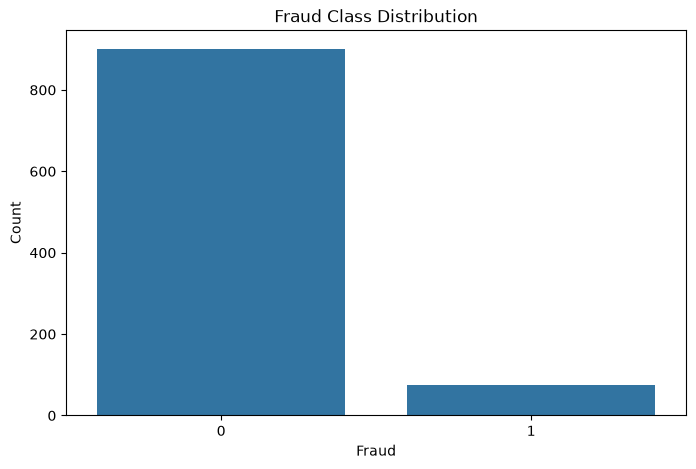

In [5]:
#now visualize the data with a countplot with the x-axis 
#being 'fraud' and the title being 'Fraud Class Distribution'
# Fraud class distribution
plt.figure(figsize=(8, 5))
sns.countplot(x='fraud', data=df)

plt.title('Fraud Class Distribution')
plt.xlabel('Fraud')
plt.ylabel('Count')

plt.show()

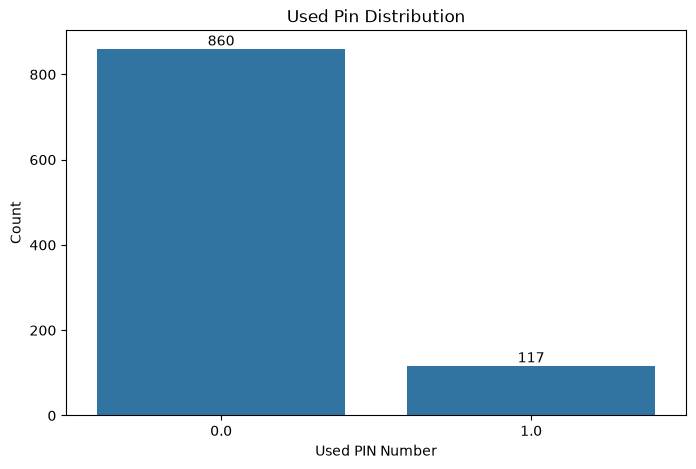

In [7]:
#next create a similar countplot of the variable "used_pin_number" titled "Used Pin Distribution" 

# Used PIN distribution
plt.figure(figsize=(8, 5))
ax = sns.countplot(x='used_pin_number', data=df)

plt.title('Used Pin Distribution')
plt.xlabel('Used PIN Number')
plt.ylabel('Count')

for container in ax.containers:
    ax.bar_label(container)

plt.show()

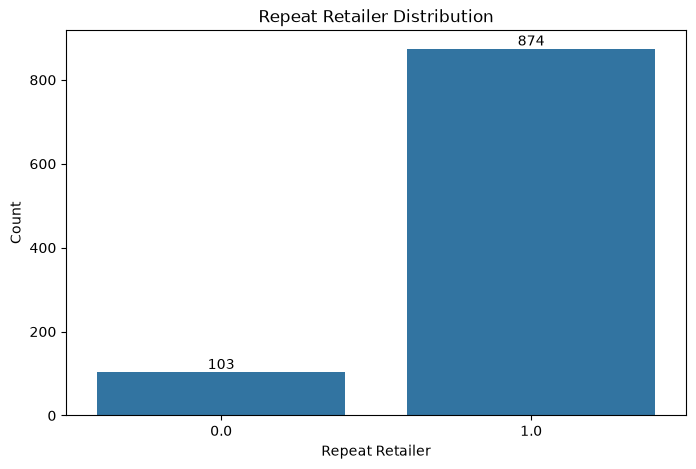

In [8]:
#next graph the variable 'repeat_retailer' with the title "Repeat Retailer Distribution"
#Repeat Retailer distribution
plt.figure(figsize=(8, 5))
ax = sns.countplot(x='repeat_retailer', data=df)

plt.title('Repeat Retailer Distribution')
plt.xlabel('Repeat Retailer')
plt.ylabel('Count')

for container in ax.containers:
    ax.bar_label(container)

plt.show()

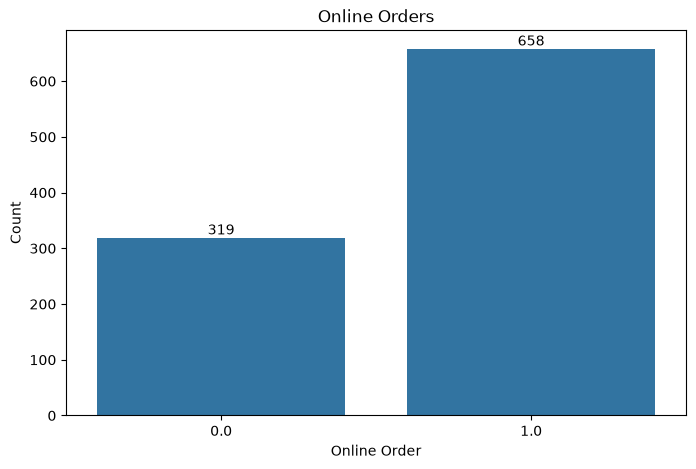

In [9]:
#next graph "online_order" titled "Online Orders" 

# Online Orders distribution
plt.figure(figsize=(8, 5))
ax = sns.countplot(x='online_order', data=df)

plt.title('Online Orders')
plt.xlabel('Online Order')
plt.ylabel('Count')

for container in ax.containers:
    ax.bar_label(container)

plt.show()

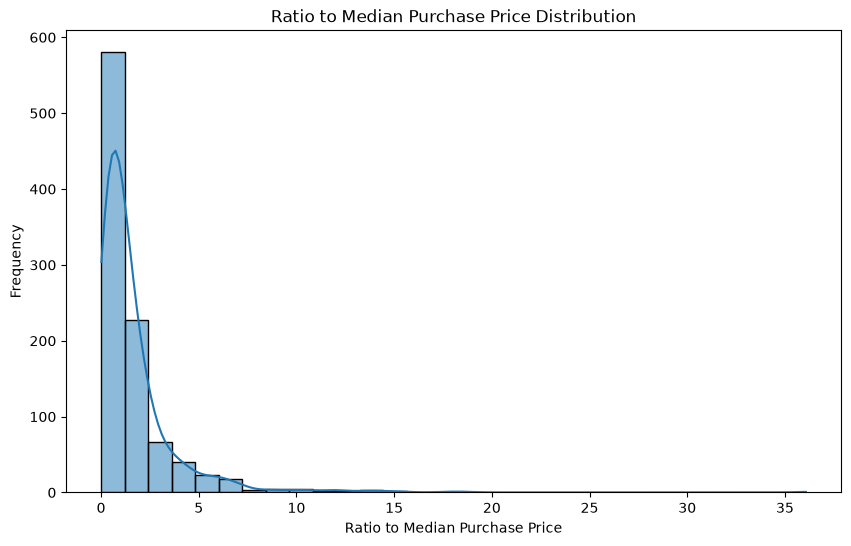

In [10]:
#next create a histogram of ratio_to_median_purchase_price

# Histogram of ratio_to_median_purchase_price
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x='ratio_to_median_purchase_price',
    bins=30,
    kde=True
)

plt.title('Ratio to Median Purchase Price Distribution')
plt.xlabel('Ratio to Median Purchase Price')
plt.ylabel('Frequency')

plt.show()

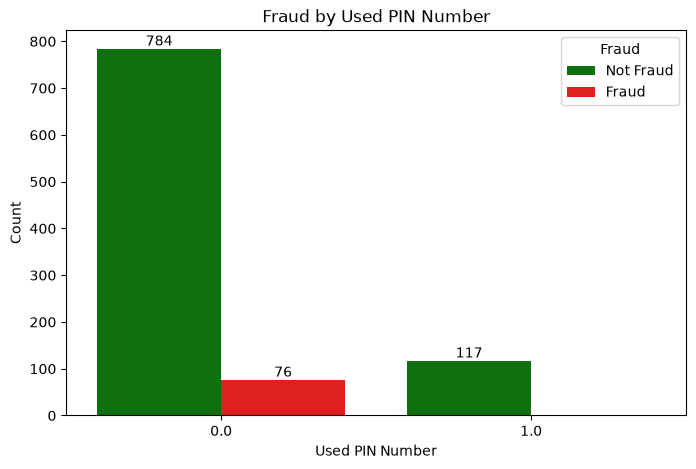

In [11]:
#moving on to bivariate analysis visualizations. create a countplot showing weather or not the charge was fraud, using the x-axis variable being 'used_pin_number" use green for not fraud, and red for fraud

# Fraud vs. Used PIN Number
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    x='used_pin_number',
    hue='fraud',
    data=df,
    palette={0: 'green', 1: 'red'}
)

plt.title('Fraud by Used PIN Number')
plt.xlabel('Used PIN Number')
plt.ylabel('Count')
plt.legend(title='Fraud', labels=['Not Fraud', 'Fraud'])

for container in ax.containers:
    ax.bar_label(container)

plt.show()

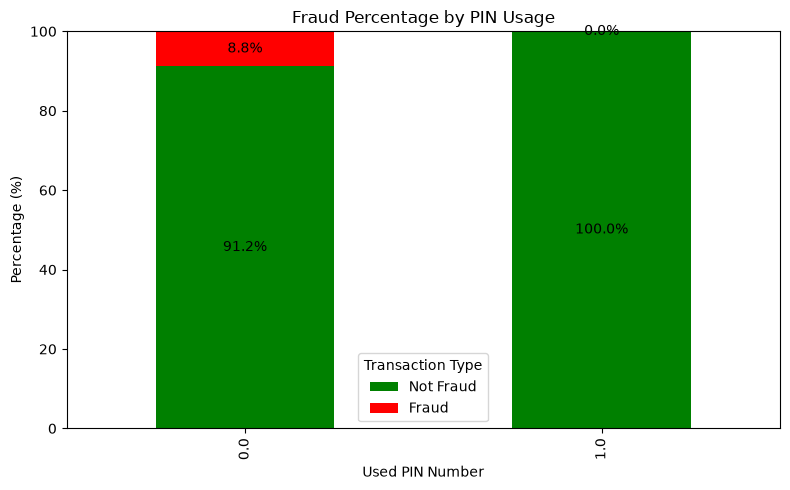

In [13]:
#next, create a percentage plot to the percentage of fraudulent transactions when a PIN was used or not, using the same variable of 'used_pin_number" stacking the fraud percent on the non fraud percent

# Calculate percentages
pin_fraud_pct = pd.crosstab(
    df['used_pin_number'],
    df['fraud'],
    normalize='index'
) * 100

# Create stacked percentage bar chart
ax = pin_fraud_pct.plot(
    kind='bar',
    stacked=True,
    figsize=(8, 5),
    color=['green', 'red']
)

plt.title('Fraud Percentage by PIN Usage')
plt.xlabel('Used PIN Number')
plt.ylabel('Percentage (%)')
plt.legend(['Not Fraud', 'Fraud'], title='Transaction Type')

# Add percentage labels
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', label_type='center')

plt.tight_layout()
plt.show()

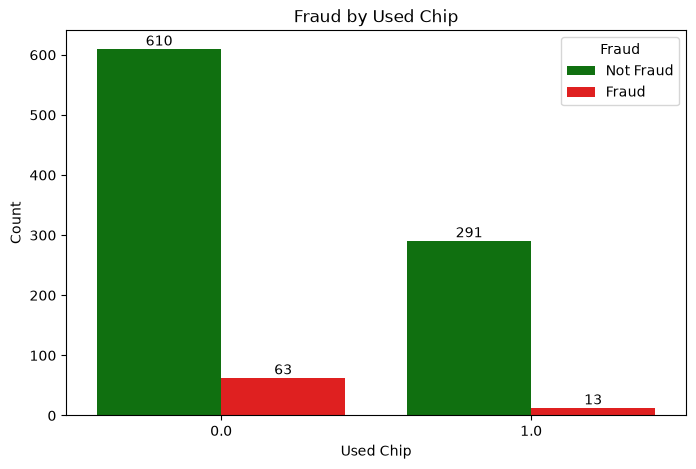

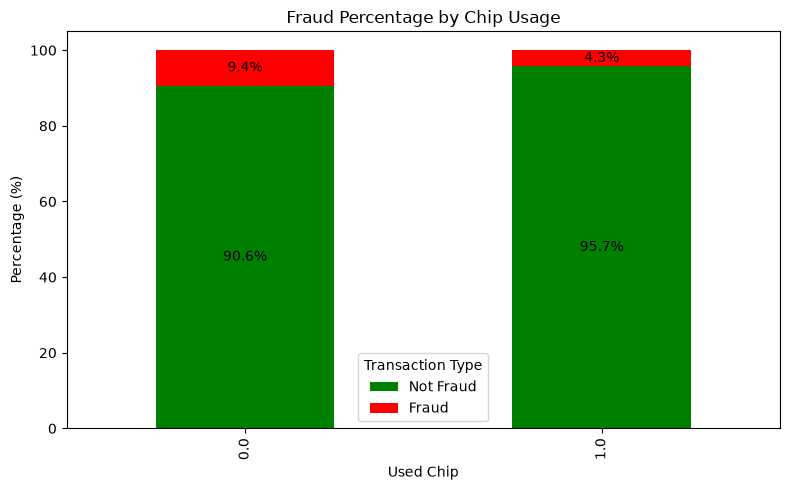

In [16]:
#do the same two plots as above but this time with the variable 'used_chip'

# Fraud vs. Used Chip
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    x='used_chip',
    hue='fraud',
    data=df,
    palette={0: 'green', 1: 'red'}
)

plt.title('Fraud by Used Chip')
plt.xlabel('Used Chip')
plt.ylabel('Count')
plt.legend(title='Fraud', labels=['Not Fraud', 'Fraud'])

for container in ax.containers:
    ax.bar_label(container)

plt.show()

# Calculate percentages
chip_fraud_pct = pd.crosstab(
    df['used_chip'],
    df['fraud'],
    normalize='index'
) * 100

# Create stacked percentage bar chart
ax = chip_fraud_pct.plot(
    kind='bar',
    stacked=True,
    figsize=(8, 5),
    color=['green', 'red']
)

plt.title('Fraud Percentage by Chip Usage')
plt.xlabel('Used Chip')
plt.ylabel('Percentage (%)')
plt.legend(['Not Fraud', 'Fraud'], title='Transaction Type')

# Add percentage labels
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', label_type='center')

plt.tight_layout()
plt.show()

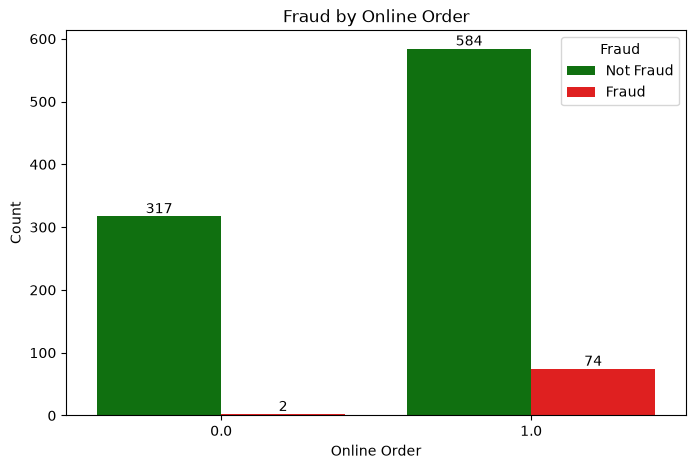

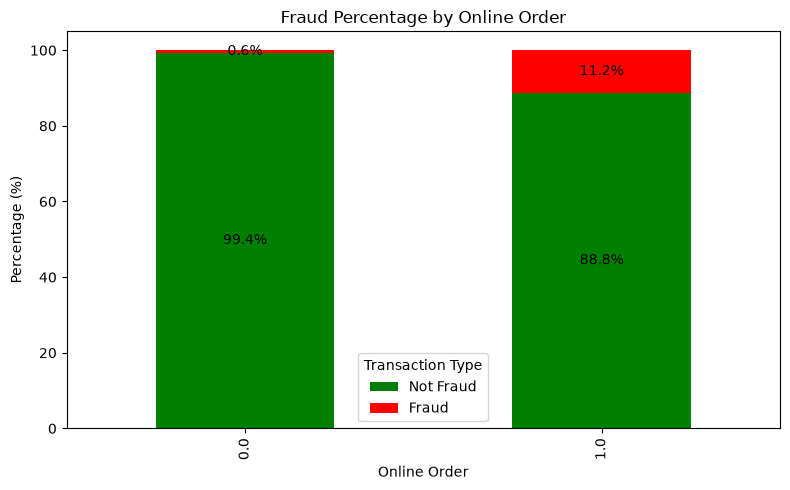

In [17]:
#next, same two plots with the variable "online_order"
# Fraud vs. Online Order
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    x='online_order',
    hue='fraud',
    data=df,
    palette={0: 'green', 1: 'red'}
)

plt.title('Fraud by Online Order')
plt.xlabel('Online Order')
plt.ylabel('Count')
plt.legend(title='Fraud', labels=['Not Fraud', 'Fraud'])

for container in ax.containers:
    ax.bar_label(container)

plt.show()

# Calculate percentages
online_fraud_pct = pd.crosstab(
    df['online_order'],
    df['fraud'],
    normalize='index'
) * 100

# Create stacked percentage bar chart
ax = online_fraud_pct.plot(
    kind='bar',
    stacked=True,
    figsize=(8, 5),
    color=['green', 'red']
)

plt.title('Fraud Percentage by Online Order')
plt.xlabel('Online Order')
plt.ylabel('Percentage (%)')
plt.legend(['Not Fraud', 'Fraud'], title='Transaction Type')

# Add percentage labels
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', label_type='center')

plt.tight_layout()
plt.show()

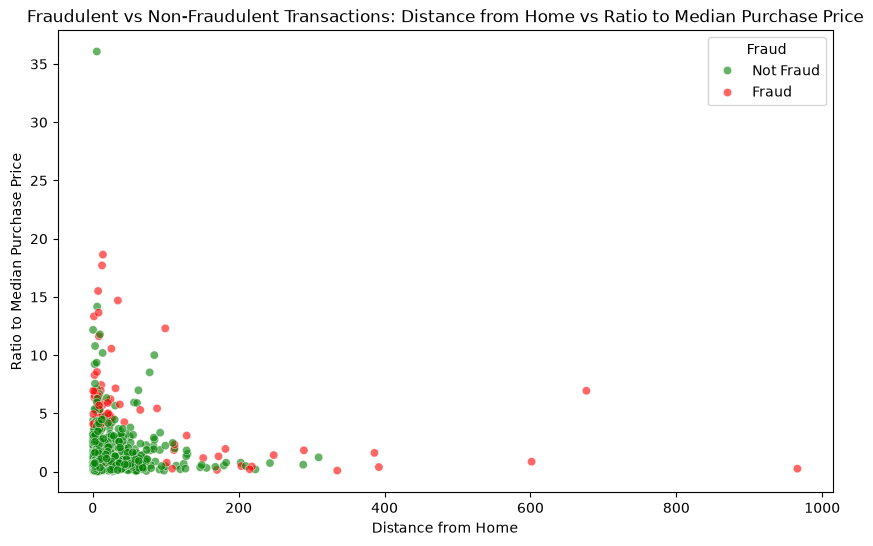

In [19]:
#next, create a scatterplot with the x variable being 'distance_from_home' and the y var being 'ratio_to_median_purchase_price' using the same color scheme, and titled: Fraudulent vs Non-Fraudulent Transactions: Distance from Home vs Ratio to Median Purchase Price
# Scatterplot: Distance from Home vs Ratio to Median Purchase Price
plt.figure(figsize=(10, 6))

ax = sns.scatterplot(
    data=df,
    x='distance_from_home',
    y='ratio_to_median_purchase_price',
    hue='fraud',
    palette={0: 'green', 1: 'red'},
    alpha=0.6
)

plt.title('Fraudulent vs Non-Fraudulent Transactions: Distance from Home vs Ratio to Median Purchase Price')
plt.xlabel('Distance from Home')
plt.ylabel('Ratio to Median Purchase Price')

# Fix legend labels while preserving colors
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, ['Not Fraud', 'Fraud'], title='Fraud')

plt.show()